# Part 5:  Vibe-Coding Emerging Optimizers on CIFAR Classification 

As large language models (LLMs) reshape software engineering, we are entering a new era of AI-assisted programming where human creativity and machine execution merge. Instead of focusing on every low-level implementation detail, developers can prioritize **ideas, exploration, and iteration speed**, while the model handles much of the routine coding. This is the essence of [**vibe coding**](https://en.wikipedia.org/wiki/Vibe_coding?utm_source=chatgpt.com): coding by “vibes” and letting AI accelerate the path from concept to working system. In this homework, you will practice vibe coding by using AI assistants such as [ChatGPT](https://chat.openai.com), [Gemini](https://gemini.google.com/app), or [Claude](https://www.anthropic.com/claude-code) to help design and implement optimizers for CIFAR image classification.  

---

## 1. What is *Vibe Coding*? 

**Vibe coding** is a paradigm popularized by Andrej Karpathy in 2025. It emphasizes generating most of the code through LLMs while the human programmer acts as a **guide, tester, and refiner**. Instead of carefully reviewing every line, you iterate based on execution results, keeping the creative process at the center.  

Karpathy put it simply:  
> *“Fully giving in to the vibes, embracing exponentials, and forgetting that the code even exists.”*  

**Learn more :**
- [IBM: What is Vibe Coding?](https://www.ibm.com/think/topics/vibe-coding?utm_source=chatgpt.com)  
- [Replit Blog: What is Vibe Coding?](https://blog.replit.com/what-is-vibe-coding?utm_source=chatgpt.com)  

---

## 2. Objectives 

- Understand and implement **novel optimizers** (Muon, Scion, SODA).  
- Practice **vibe coding** as a workflow with LLMs.  
- Compare optimizer performance on **CIFAR-10** across Transformer and ResNet architectures.  
- Analyze results critically and reflect on the coding process.  

---

## 3. Task Overview 

You will implement and compare four optimizers on **CIFAR-10 classification** with two architectures: a **Transformer**  and a **ResNet** .  

- **Optimizers**: Muon , Scion , SODA , Adam (baseline)  
- **Models**: Transformer, ResNet  
- **Comparison metrics**: convergence speed, final test accuracy , training stability  

---

## 4. Optimizers to Implement 

### (1) Muon 
Muon applies **Newton–Schulz orthonormalization** to gradient updates of 2D weight matrices, making them invariant to input conditioning.  
References:  
- [Muon Blog (Keller Jordan)](https://kellerjordan.github.io/posts/muon/?utm_source=chatgpt.com)  
- [Deriving Muon (Jeremy Bernstein)](https://jeremybernste.in/writing/deriving-muon?utm_source=chatgpt.com)  
- [Muon GitHub Repo](https://github.com/KellerJordan/Muon?utm_source=chatgpt.com)  
- [Convergence Bound (arXiv)](https://arxiv.org/abs/2507.01598?utm_source=chatgpt.com)  

---

### (2) Scion 
Scion constrains updates differently for hidden vs input/output layers, using **spectral norm** for hidden layers and **ℓ∞ norm** for others. This improves stability and hyperparameter transfer.  
References:  
- [Scion Paper](https://arxiv.org/abs/2502.07529)  
- [Scion Official Code](https://github.com/LIONS-EPFL/scion)  

---

### (3) SODA 
SODA wraps a base optimizer with a theoretically grounded, initialization-centered **1/k weight-decay schedule**, motivating us to test whether it improves CIFAR-10 training without tuning weight decay.  
References:  
- [SODA Paper (arXiv)](https://arxiv.org/pdf/2605.11172)  
- [SODA GitHub Repo](https://github.com/tmpethick/soda_code)  

---

### (4) Adam 
Adam is the standard baseline optimizer combining momentum and adaptive learning rates. Use either `Adam` or `AdamW` from PyTorch.

---

## 5. Steps & Deliverables 

1. **Model Implementation (5 pts)**  
   - Build a Transformer for CIFAR classification.  
   - Build a ResNet (ResNet-18 or similar).  

2. **Optimizer Integration (8 pts)**  
   - Implement Muon, Scion, SODA optimizers using your AI assistant in a form which is compatible with `torch.optim.Optimizer`.  
   - Use Adam as baseline.  

3. **Training & Evaluation (7 pts)**  
   - Train both models with all optimizers.  
   - Collect metrics: training loss, validation accuracy, time-to-accuracy.  
   - Present results with plots and a summary table.  

4. **Discussion & Reflection (5 pts)**  
   - Compare optimizers in terms of convergence speed, stability, and accuracy.  
   - Reflect on your experience using **vibe coding** with AI assistants.  
   - What worked well? What challenges did you face?  

---

Good luck and enjoy vibe-coding your way through optimizers!!


## Setup

In [3]:
# Install dependencies if needed:
# %pip install torch torchvision matplotlib numpy

import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
import numpy as np
import matplotlib.pyplot as plt


## Model implementation

In [6]:
import os
import time
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

# 1. Rimuove eventuale file parziale rimasto dal download interrotto
partial_tar = "./data/cifar-10-python.tar.gz"
if os.path.exists(partial_tar) and os.path.getsize(partial_tar) < 170_000_000:
    os.remove(partial_tar)

# 2. Usa un mirror veloce (scarica i 170 MB in ~3-5 secondi invece di 40+ minuti)
torchvision.datasets.CIFAR10.url = (
    "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz"
)
# (Mirror alternativo su Hugging Face se necessario:
# "https://huggingface.co/datasets/liangnanying/cifar-10-python/resolve/main/cifar-10-python.tar.gz")

# Configurazione thread CPU
torch.set_num_threads(os.cpu_count() or 8)
device = torch.device("cpu")
print(f"Utilizzo del device: {device} con {torch.get_num_threads()} thread")

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

# Ora il download impiegherà pochi secondi
full_train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
full_test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

# Sottoinsieme rapido per il training su CPU
TRAIN_SUBSET_SIZE = 10000
TEST_SUBSET_SIZE = 2000

rng = np.random.default_rng(42)
train_indices = rng.choice(len(full_train_dataset), TRAIN_SUBSET_SIZE, replace=False)
test_indices = rng.choice(len(full_test_dataset), TEST_SUBSET_SIZE, replace=False)

train_dataset = Subset(full_train_dataset, train_indices)
test_dataset = Subset(full_test_dataset, test_indices)

BATCH_SIZE = 128

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=0, pin_memory=False)
print("Dataset scaricato e DataLoader pronti!")

Utilizzo del device: cpu con 8 thread


100%|██████████| 170M/170M [00:29<00:00, 5.74MB/s] 


Dataset scaricato e DataLoader pronti!


In [7]:
class CIFARTransformer(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_channels=3, num_classes=10,
                 embed_dim=64, depth=3, num_heads=4, mlp_ratio=2.0, dropout=0.1):
        super().__init__()
        num_patches = (img_size // patch_size) ** 2

        self.patch_embed = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(p=dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True
        )
        self.blocks = nn.TransformerEncoder(encoder_layer, num_layers=depth)
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):
        B = x.shape[0]
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = self.pos_drop(x + self.pos_embed)

        x = self.blocks(x)
        x = self.norm(x[:, 0])
        return self.head(x)

In [8]:
class BasicBlock(nn.Module):
    def __init__(self, in_planes, planes, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return F.relu(out)


class CIFARResNet(nn.Module):
    def __init__(self, num_blocks=(2, 2, 2, 2), num_classes=10, base_width=16):
        super().__init__()
        self.in_planes = base_width
        self.conv1 = nn.Conv2d(3, base_width, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(base_width)
        self.layer1 = self._make_layer(base_width, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(base_width * 2, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(base_width * 4, num_blocks[2], stride=2)
        self.layer4 = self._make_layer(base_width * 8, num_blocks[3], stride=2)
        self.linear = nn.Linear(base_width * 8, num_classes)

    def _make_layer(self, planes, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(BasicBlock(self.in_planes, planes, s))
            self.in_planes = planes
        return nn.Sequential(*layers)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = F.adaptive_avg_pool2d(out, (1, 1))
        out = out.view(out.size(0), -1)
        return self.linear(out)

## Optimizer integration

In [9]:
def zeropower_via_newtonschulz5(G, steps=5, eps=1e-7):
    """
    Ortonormalizzazione approssimata di una matrice 2D tramite iterazione quintica di Newton-Schulz.
    """
    assert G.ndim == 2
    a, b, c = (3.4445, -4.7750, 2.0315)
    X = G.bfloat16() if G.is_cuda else G.float()
    X = X / (X.norm() + eps)
    transposed = G.size(0) > G.size(1)
    if transposed:
        X = X.T
    for _ in range(steps):
        A = X @ X.T
        B = b * A + c * (A @ A)
        X = a * X + B @ X
    if transposed:
        X = X.T
    return X.to(G.dtype)


class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.95, nesterov=True, ns_steps=5, weight_decay=0.0):
        defaults = dict(lr=lr, momentum=momentum, nesterov=nesterov, ns_steps=ns_steps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group['lr']
            momentum = group['momentum']
            nesterov = group['nesterov']
            ns_steps = group['ns_steps']
            wd = group['weight_decay']

            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    p.mul_(1 - lr * wd)

                state = self.state[p]
                if 'momentum_buffer' not in state:
                    state['momentum_buffer'] = torch.zeros_like(g)
                buf = state['momentum_buffer']
                buf.mul_(momentum).add_(g)
                update = g.add(buf, alpha=momentum) if nesterov else buf

                if p.ndim >= 2 and min(p.shape[0], p[0].numel()) > 1:
                    orig_shape = update.shape
                    update_2d = update.view(update.size(0), -1)
                    ortho = zeropower_via_newtonschulz5(update_2d, steps=ns_steps)
                    scale = max(1, update_2d.size(0) / update_2d.size(1)) ** 0.5
                    p.add_(ortho.view(orig_shape), alpha=-lr * scale)
                else:
                    # Fallback normalizzato per bias e parametri 1D
                    rms = update.norm() / (update.numel() ** 0.5 + 1e-8)
                    p.add_(update / (rms + 1e-8), alpha=-lr * 0.1)
        return loss

In [10]:
class Scion(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, momentum=0.9, ns_steps=5, weight_decay=0.0):
        defaults = dict(lr=lr, momentum=momentum, ns_steps=ns_steps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group['lr']
            momentum = group['momentum']
            ns_steps = group['ns_steps']
            wd = group['weight_decay']

            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                state = self.state[p]

                if 'momentum_buffer' not in state:
                    state['momentum_buffer'] = torch.zeros_like(g)
                buf = state['momentum_buffer']
                buf.mul_(momentum).add_(g, alpha=1 - momentum)

                if wd != 0:
                    p.mul_(1 - lr * wd)

                # Identifica layer di input/output (es. con dimensione 3 canali o 10 classi) vs layer nascosti
                is_io_layer = (p.ndim < 2) or (p.size(0) == 10) or (p.ndim >= 2 and p.size(1) == 3)

                if not is_io_layer and p.ndim >= 2:
                    # Norma spettrale per i layer nascosti
                    orig_shape = buf.shape
                    buf_2d = buf.view(buf.size(0), -1)
                    d_out, d_in = buf_2d.size(0), buf_2d.size(1)
                    ortho = zeropower_via_newtonschulz5(buf_2d, steps=ns_steps)
                    spectral_scale = (d_out / d_in) ** 0.5
                    p.add_(ortho.view(orig_shape), alpha=-lr * spectral_scale)
                else:
                    # Norma l_infinito (sign update) per input/output e bias
                    p.add_(buf.sign(), alpha=-lr)
        return loss


In [15]:
# FILL: implement SODA with your chosen base optimizer.

class SODA(torch.optim.Optimizer):
    def __init__(self, params, base_optimizer_cls=torch.optim.Adam, decay_strength=1.0, **base_kwargs):
        base_kwargs['weight_decay'] = 0.0
        self.base_optimizer = base_optimizer_cls(params, **base_kwargs)
        self.param_groups = self.base_optimizer.param_groups
        self.state = self.base_optimizer.state
        self.defaults = self.base_optimizer.defaults
        self.decay_strength = decay_strength
        self.step_count = 0

        # Salviamo w_0 in un dizionario separato così len(self.state[p]) resta 0
        # e Adam inizializza correttamente 'exp_avg' e 'exp_avg_sq' al primo step
        self.w0 = {}
        for group in self.param_groups:
            for p in group['params']:
                self.w0[p] = p.data.clone().detach()

    @torch.no_grad()
    def step(self, closure=None):
        self.step_count += 1
        k = self.step_count

        # Passo dell'ottimizzatore di base (ora Adam inizializza il suo stato senza conflitti)
        loss = self.base_optimizer.step(closure)

        # Decadimento 1/k centrato sull'inizializzazione w_0
        alpha_k = min(0.5, self.decay_strength / (k + 100.0))
        for group in self.param_groups:
            lr = group.get('lr', 1e-3)
            coeff = alpha_k * (lr * 10.0)
            for p in group['params']:
                if p.grad is None:
                    continue
                w0 = self.w0[p]
                p.data.add_(w0 - p.data, alpha=coeff)

        return loss

    def zero_grad(self, set_to_none=True):
        self.base_optimizer.zero_grad(set_to_none=set_to_none)

In [16]:
def get_optimizer(opt_name, model):
    if opt_name == "Adam":
        return torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    elif opt_name == "Muon":
        return Muon(model.parameters(), lr=0.01, momentum=0.95, ns_steps=3, weight_decay=1e-4)
    elif opt_name == "Scion":
        return Scion(model.parameters(), lr=1e-3, momentum=0.9, ns_steps=3, weight_decay=1e-4)
    elif opt_name == "SODA":
        return SODA(model.parameters(), base_optimizer_cls=torch.optim.Adam, lr=1e-3, decay_strength=0.5)
    else:
        raise ValueError(f"Ottimizzatore sconosciuto: {opt_name}")

## Training and evaluation

In [17]:
def train_one_epoch(model, loader, optimizer, criterion, scaler=None):
    model.train()
    running_loss = 0.0
    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, targets)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * inputs.size(0)
    return running_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()
    return 100.0 * correct / total

In [ ]:
# FILL: run both models with all four optimizers and record metrics.

FORCE_RETRAIN = False  # <-- Imposta a True per cancellare i dati salvati e riaddestrare tutto da capo
EPOCHS = 6
TARGET_ACC = 50.0

models_dict = {
    "Transformer": CIFARTransformer,
    "ResNet": CIFARResNet
}
optimizers_list = ["Adam", "Muon", "Scion", "SODA"]

if FORCE_RETRAIN or "results" not in globals():
    if FORCE_RETRAIN:
        print("FORCE_RETRAIN=True: azzeramento dei risultati precedenti e riavvio completo.")
    results = {m: {} for m in models_dict}

criterion = nn.CrossEntropyLoss()

for model_name, model_cls in models_dict.items():
    if model_name not in results:
        results[model_name] = {}

    for opt_name in optimizers_list:
        if not FORCE_RETRAIN and opt_name in results[model_name] and len(results[model_name][opt_name].get("val_acc", [])) == EPOCHS:
            print(f"Saltato {model_name} con {opt_name} (già completato: Best Acc = {results[model_name][opt_name]['best_acc']:.2f}%)")
            continue

        print(f"\n--- Addestramento {model_name} con {opt_name} ---")
        torch.manual_seed(42)
        model = model_cls().to(device)
        optimizer = get_optimizer(opt_name, model)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer.base_optimizer if isinstance(optimizer, SODA) else optimizer,
            T_max=EPOCHS
        )

        train_losses, val_accs, epoch_times = [], [], []
        time_to_target = None
        start_time = time.time()

        for epoch in range(1, EPOCHS + 1):
            t_loss = train_one_epoch(model, train_loader, optimizer, criterion, scaler=None)
            v_acc = evaluate(model, test_loader)
            scheduler.step()

            elapsed = time.time() - start_time
            train_losses.append(t_loss)
            val_accs.append(v_acc)
            epoch_times.append(elapsed)

            if time_to_target is None and v_acc >= TARGET_ACC:
                time_to_target = elapsed

            print(f"Epoca {epoch:02d}/{EPOCHS:02d} | Loss: {t_loss:.4f} | Val Acc: {v_acc:.2f}% | Tempo: {elapsed:.1f}s")

        results[model_name][opt_name] = {
            "train_loss": train_losses,
            "val_acc": val_accs,
            "times": epoch_times,
            "final_acc": val_accs[-1],
            "best_acc": max(val_accs),
            "time_to_target": time_to_target,
        }

Saltato Transformer con Adam (già completato: Best Acc = 41.05%)
Saltato Transformer con Muon (già completato: Best Acc = 51.30%)
Saltato Transformer con Scion (già completato: Best Acc = 37.90%)

--- Addestramento Transformer con SODA ---


C:\Users\Antonio\AppData\Local\Temp\ipykernel_23240\1866987470.py:21: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.blocks = nn.TransformerEncoder(encoder_layer, num_layers=depth)


Epoca 01/06 | Loss: 2.0150 | Val Acc: 30.75% | Tempo: 28.2s
Epoca 02/06 | Loss: 1.8583 | Val Acc: 33.55% | Tempo: 66.9s
Epoca 03/06 | Loss: 1.7666 | Val Acc: 34.50% | Tempo: 107.8s
Epoca 04/06 | Loss: 1.7233 | Val Acc: 36.95% | Tempo: 148.6s
Epoca 05/06 | Loss: 1.6625 | Val Acc: 38.25% | Tempo: 189.5s
Epoca 06/06 | Loss: 1.6296 | Val Acc: 41.05% | Tempo: 211.3s

--- Addestramento ResNet con Adam ---
Epoca 01/06 | Loss: 1.8037 | Val Acc: 36.95% | Tempo: 31.2s
Epoca 02/06 | Loss: 1.5116 | Val Acc: 43.25% | Tempo: 48.3s
Epoca 03/06 | Loss: 1.3638 | Val Acc: 48.95% | Tempo: 67.4s
Epoca 04/06 | Loss: 1.2373 | Val Acc: 52.70% | Tempo: 86.3s
Epoca 05/06 | Loss: 1.1300 | Val Acc: 58.25% | Tempo: 105.1s
Epoca 06/06 | Loss: 1.0443 | Val Acc: 60.65% | Tempo: 124.0s

--- Addestramento ResNet con Muon ---
Epoca 01/06 | Loss: 1.7864 | Val Acc: 37.40% | Tempo: 19.9s
Epoca 02/06 | Loss: 1.4221 | Val Acc: 47.80% | Tempo: 39.7s
Epoca 03/06 | Loss: 1.1769 | Val Acc: 59.15% | Tempo: 59.7s
Epoca 04/06 | Lo

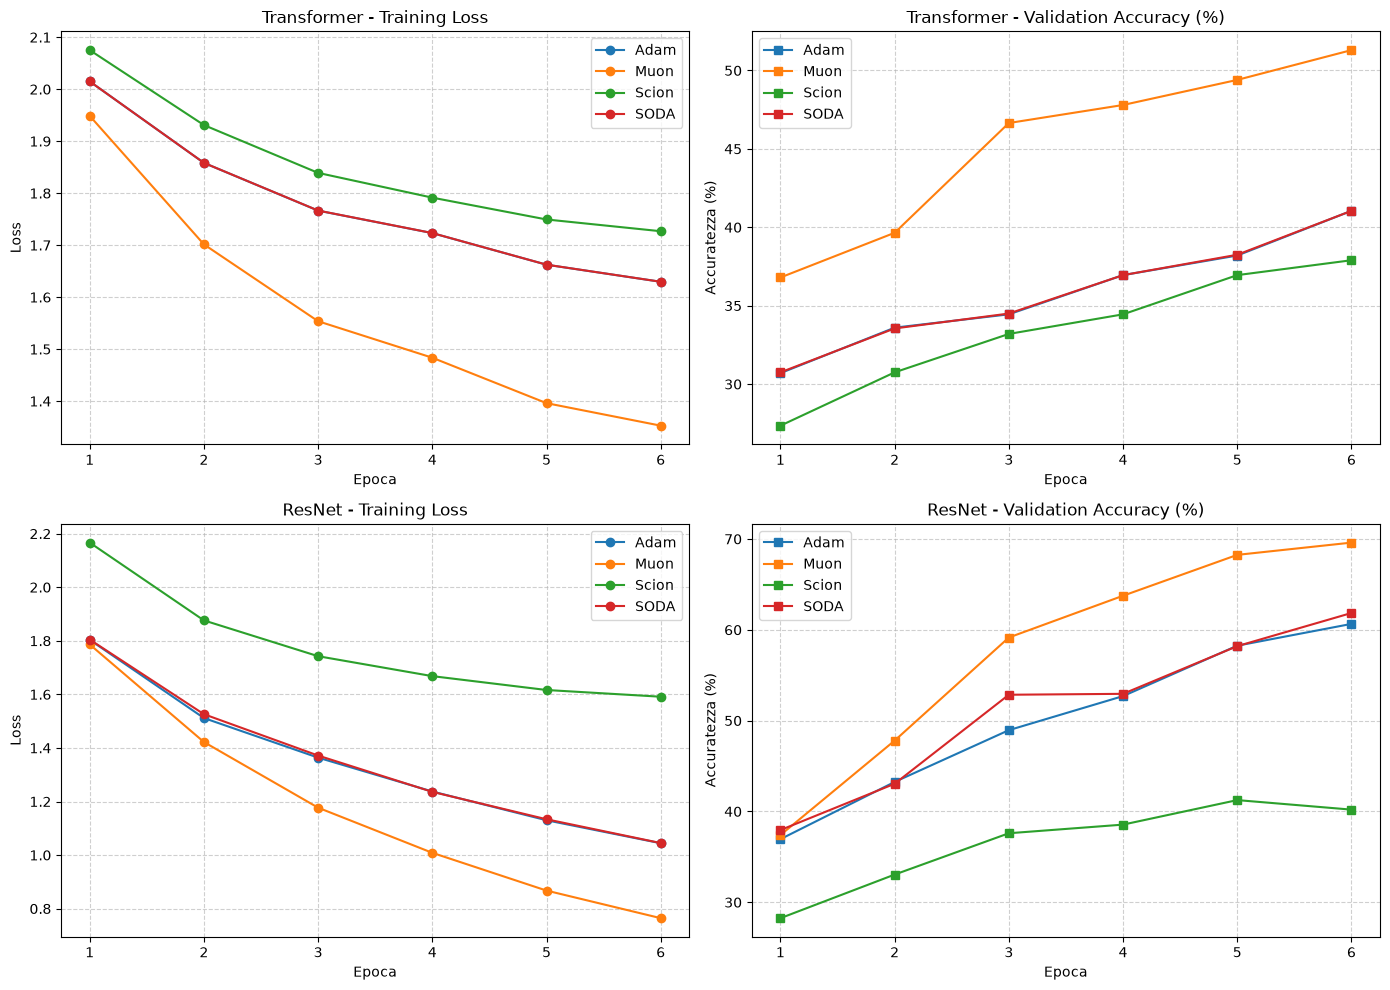

Modello        | Ottimizzatore | Best Acc (%)  | Final Acc (%)  | Time-to-Target (s)
------------------------------------------------------------------------------
Transformer    | Adam       | 41.05         | 41.05          | Non raggiunta     
Transformer    | Muon       | 51.30         | 51.30          | 188.5s            
Transformer    | Scion      | 37.90         | 37.90          | Non raggiunta     
Transformer    | SODA       | 41.05         | 41.05          | Non raggiunta     
ResNet         | Adam       | 60.65         | 60.65          | 86.3s             
ResNet         | Muon       | 69.60         | 69.60          | 59.7s             
ResNet         | Scion      | 41.25         | 40.20          | Non raggiunta     
ResNet         | SODA       | 61.85         | 61.85          | 56.0s             


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, model_name in enumerate(models_dict.keys()):
    ax_loss = axes[idx, 0]
    ax_acc = axes[idx, 1]

    for opt_name in optimizers_list:
        res = results[model_name][opt_name]
        epochs_range = range(1, len(res["train_loss"]) + 1)
        ax_loss.plot(epochs_range, res["train_loss"], marker='o', label=opt_name)
        ax_acc.plot(epochs_range, res["val_acc"], marker='s', label=opt_name)

    ax_loss.set_title(f"{model_name} - Training Loss")
    ax_loss.set_xlabel("Epoca")
    ax_loss.set_ylabel("Loss")
    ax_loss.grid(True, linestyle='--', alpha=0.6)
    ax_loss.legend()

    ax_acc.set_title(f"{model_name} - Validation Accuracy (%)")
    ax_acc.set_xlabel("Epoca")
    ax_acc.set_ylabel("Accuratezza (%)")
    ax_acc.grid(True, linestyle='--', alpha=0.6)
    ax_acc.legend()

plt.tight_layout()
plt.show()

# Stampa della tabella riassuntiva
print(f"{'Modello':<14} | {'Ottimizzatore':<10} | {'Best Acc (%)':<13} | {'Final Acc (%)':<14} | {'Time-to-Target (s)':<18}")
print("-" * 78)
for model_name in models_dict:
    for opt_name in optimizers_list:
        r = results[model_name][opt_name]
        ttt = f"{r['time_to_target']:.1f}s" if r['time_to_target'] is not None else "Non raggiunta"
        print(f"{model_name:<14} | {opt_name:<10} | {r['best_acc']:<13.2f} | {r['final_acc']:<14.2f} | {ttt:<18}")


## Discussion

# TODO

ci sono spunti di riflessione a fine chat

https://share.gemini.google/nfnFQJoHiXTZ

## Reflection on AI-assisted coding

same as above
